# QPDK resonator test chip — 16 λ/4 resonators on two probelines (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/resonator_test_chip.py`
(`resonator_test_chip_python`) and its frozen netlist `resonator_test_chip_yaml.pic.yml`,
<https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024; depth-1 clone read
2026-11-03, never executed). Spec: `docs/designs/qpdk/resonator_test_chip.md`. Two straight west → east
probelines, 1000 µm apart, each between two launchers, each with eight shorted λ/4 CPW resonators
(`quarter_wave_resonator_coupled`, 6 meanders, 200 µm coupled section): bottom-line resonators hang below their
line, top-line ones (mirrored) above it. A loss / kinetic-inductance test chip; no qubits.

This notebook **rebuilds** the chip on the Quantcore PDK (not a replica); we distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 9.2 × 4.3 mm (the filled variant's chip edge) | the same 9.2 × 4.3 mm (it does not fit the 7.5 mm die), Quantcore die frame, device ID "QPDK-RTC"; Designer = source + (100, 1650) µm before centring |
| pads | QPDK `launcher` at the chip edge | `BondPad`s **100 µm** (`frame.pad_edge`) in from the die edge (`edge="auto"`; at the source position their etch touched the edge) |
| placement | — | the resonators centred between the pads: shifted **−106 µm** in x |
| substrate | Al on Si (εr 11.45) | sapphire 650 µm, εr 10.25 (frequencies are not the QPDK ones) |
| junctions | none | none |
| cheese | none in `resonator_test_chip_python` (QPDK's `filled_resonator_test_chip` adds a vortex fill; not this rebuild) | the **PDK band** (chip `cheese: "auto"`, at least 4 µm clear of 3/0) |
| resonators | — | kept: the 16 lengths `np.linspace(0.9, 1.275, 16) × 4000 µm` (3600 … 5100 µm in 100 µm steps, interleaved: even indices on the bottom line, odd on the top), the 1000 µm pitch, the 200 µm coupled sections, the short at each coupled section's west end, 6 meanders, the 16 µm resonator–probeline gap (4 µm KQC ground strip), CPW 10/6 µm, bend r 100 µm |

**Simplified:** the probelines run straight on the launcher axis (QPDK adds a small S-bend at each launcher, its
line sits 26 µm off the axis); each meander is the router's KQC `Meander` between the open end and the coupled
section (same total length and turn count); the README's "varied CPW widths and gaps" is not in the code or
YAML, so it is not reproduced. **Open ends:** each resonator starts at a 6 µm `CpweOpenEnd` gap, the same 6 µm
etched open end as QPDK's `open_start`.

**Fixed here:** the hanger couplers are anchored by position (`near=(x, y)` on the probeline) instead of an
arclength from the launcher, so the pad rule's 100 µm shift of the launchers leaves them at the source positions.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in step 13 (`qcc mask` does the
full file). `_qpdk` holds the QPDK cell defaults shared by the QPDK notebooks (launcher, double-pad transmon,
IDC, the trilayer SQUID, the die box and the centring check).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
import _qpdk as QP                               # QPDK cell defaults, trilayer SQUID, die box, centring
from quantcore_circuits.designer import Designer
import numpy as np
LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export
OUT = Path("examples/designs/qpdk")              # design JSON + final snapshots
STEPS = Path("build/snapshots/resonator_test_chip")           # step-by-step snapshots (build/ is not kept in the repo)
DX, DY = 100, 1650                               # Designer = QPDK source + (DX, DY), before centring

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

**Junctions:** none on this chip (resonators only), so the PDK junction rule is not used.

## 3 · The die and its frame

The source's 9.2 × 4.3 mm chip with the Quantcore die frame and the device ID "QPDK-RTC". No `with_grid`: the
source has no cheese, so the build draws the PDK band.

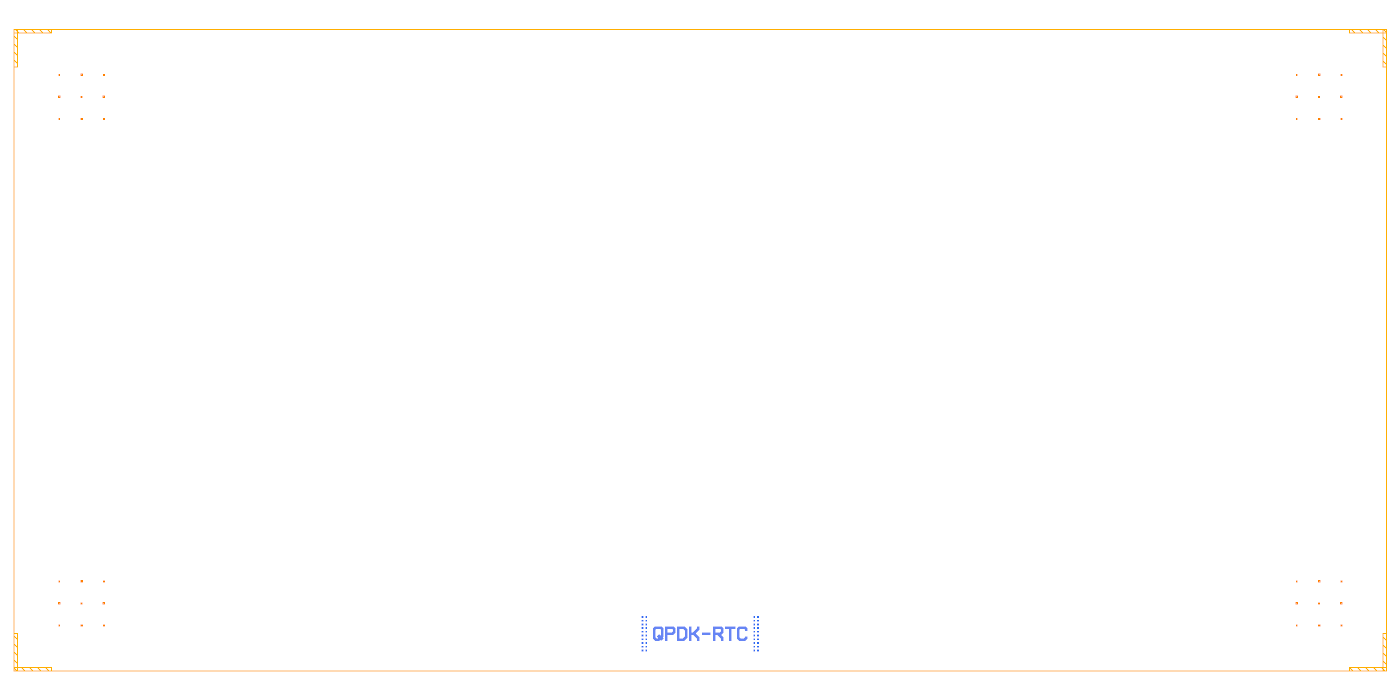

In [4]:
W, H = 9200, 4300
d = Designer("resonator_test_chip", box=(0, 0, W, H), chip={"name_chip": "QPDK-RTC"}, live=LIVE)
snap(d, STEPS / "1_die.png", size=(1400, 700), width=560);

## 4 · Pads and the pad rule

QPDK's `launcher` (a 200 × 200 µm wire-bond pad on a 200/110 µm CPW, a 100 µm taper to the 10/6 µm line) is a
KQC-style `BondPad` here (`QP.LAUNCHER`). **PDK rule:** the outer etch edge of a pad sits `frame.pad_edge`
(100 µm) from the die edge. `edge="auto"` in `d.add` applies it: the pad keeps its position along the
nearest die edge (the source's launcher axis) and slides perpendicular to it until its etch ends 100 µm from
the edge. The lead routes to the circuit simply get longer; nothing else moves. The table shows each pad's
distance after the rule (✓ = 100 µm).
Four launchers: each probeline between a west and an east launcher, at y = 1650 and 2650 µm. QPDK draws them
with their etch at the chip edge; the rule moves them 100 µm in (each probeline is 200 µm shorter).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PW_B | `BondPad` | w | 100.0 | ✓ |
| PE_B | `BondPad` | e | 100.0 | ✓ |
| PW_T | `BondPad` | w | 100.0 | ✓ |
| PE_T | `BondPad` | e | 100.0 | ✓ |

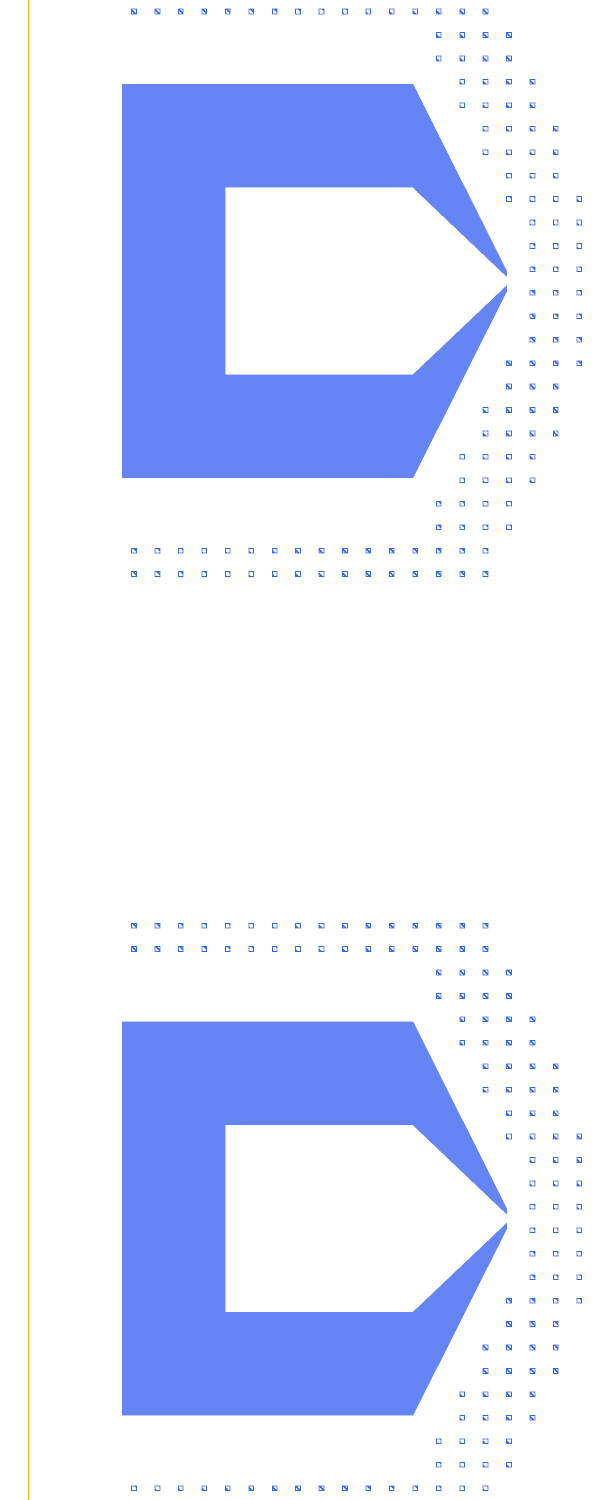

In [5]:
with d.batch():
    for line, y in (("B", DY), ("T", DY + 1000)):
        d.add(f"PW_{line}", "BondPad", at=(QP.LAUNCHER_DEPTH, y), rot=270, edge="auto", **QP.LAUNCHER)
        d.add(f"PE_{line}", "BondPad", at=(W - QP.LAUNCHER_DEPTH, y), rot=90, edge="auto", **QP.LAUNCHER)
rebuild(d)
display(Markdown(pads_md(d)))
snap(d, STEPS / "2_pads.png", box=(-20, DY - 300, 600, DY + 1300), size=(600, 1500), width=260);

## 5 · Components

Sixteen 6 µm open ends (`CpweOpenEnd`, length 6 µm: QPDK's `open_start` etch), one per resonator, 1250 µm from
its probeline, 100 µm east of the coupled-section centre `xc = source 1000 k + 100` (k = 1 … 8). The resonator
lengths: even indices on the bottom line, odd on the top.

{'B': [3600, 3800, 4000, 4200, 4400, 4600, 4800, 5000], 'T': [3700, 3900, 4100, 4300, 4500, 4700, 4900, 5100]}


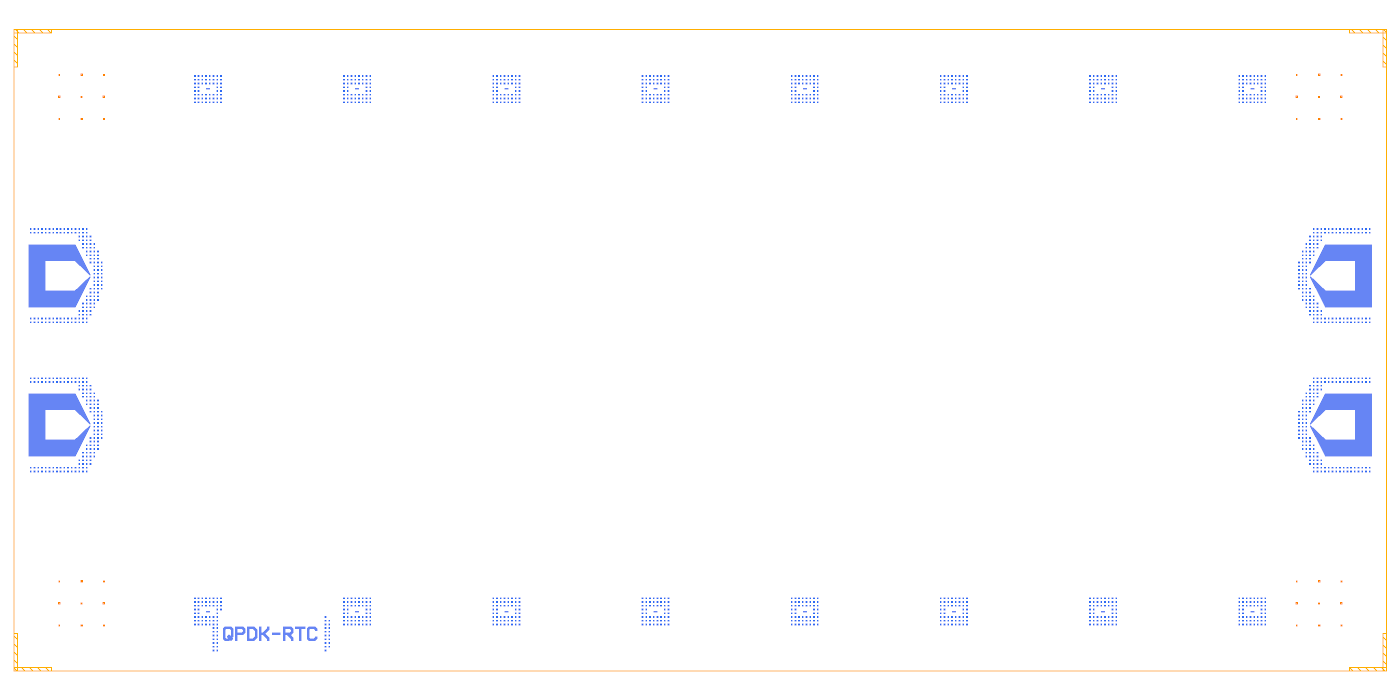

In [6]:
lengths = np.linspace(0.9 * 4000, 1.275 * 4000, 16)
LINES = (("B", DY, "right", -1, lengths[0::2]), ("T", DY + 1000, "left", +1, lengths[1::2]))
with d.batch():
    for line, y, side, sgn, ls in LINES:
        for k in range(1, 9):
            xc = DX + 1000 * k + 100                   # coupled-section centre (source 1000 k + 100)
            d.add(f"OE_{line}{k}", "CpweOpenEnd", at=(xc + 100, y + sgn * 1250), rot=90 * sgn, length=6)
print({line: [round(L) for L in ls] for line, _, _, _, ls in LINES})
snap(d, STEPS / "3_components.png", size=(1400, 700), width=560);

## 6 · Routes

**Probelines** straight from launcher to launcher (r = 100 µm). **Resonators:** from each open end a meander
(6 turns, r = 75 µm) to a 200 µm coupled section hanging on the probeline —
`fl.hanger(near=(xc, y), length=200, side=..., ground_gap=4, direction="backward", end="short")`: centred at the
probeline point nearest (xc, y), 4 µm ground strip (QPDK's 16 µm line-to-line gap), shorted at its west end
(`direction="backward"`) → λ/4. One sim group per probeline with its eight resonators (eigenmode only: a shorted
λ/4 is ground in a C-matrix).

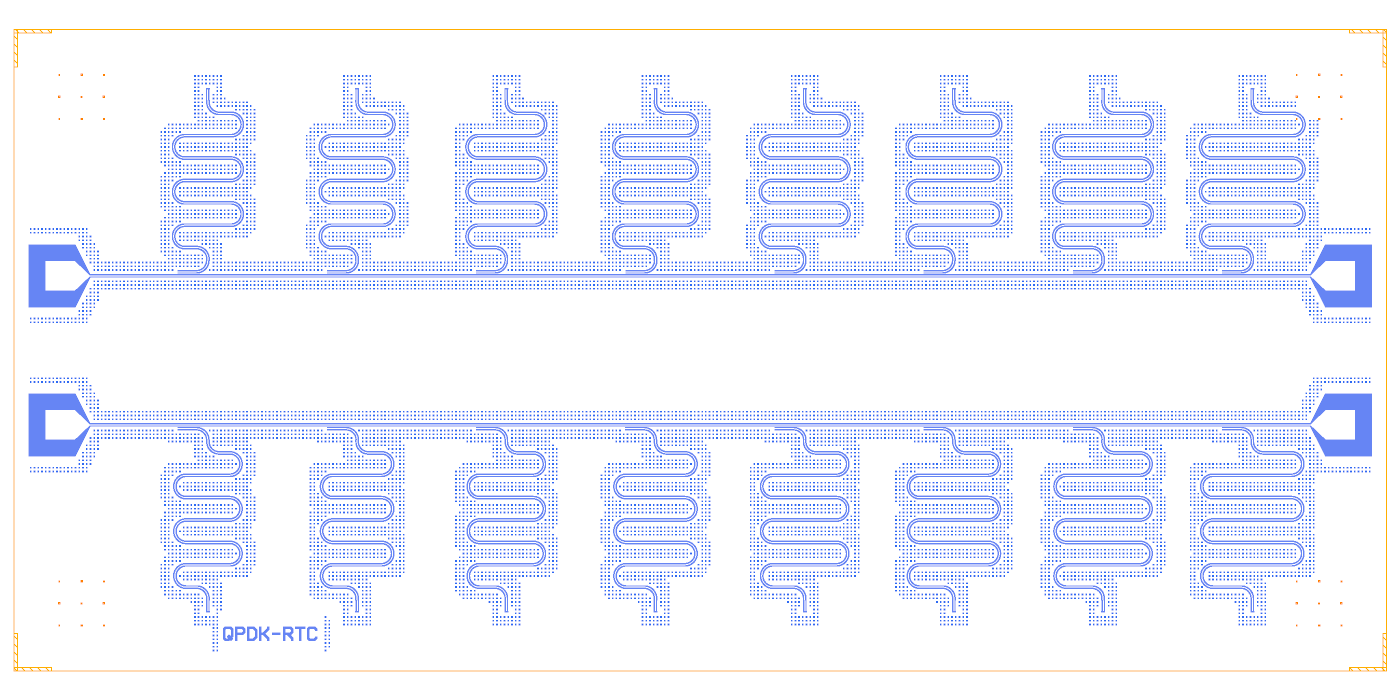

{'RB1': 3600.0, 'RB2': 3800.0, 'RB3': 4000.0, 'RB4': 4200.0, 'RB5': 4400.0, 'RB6': 4600.0, 'RB7': 4800.0, 'RB8': 5000.0, 'RT1': 3700.0, 'RT2': 3900.0, 'RT3': 4100.0, 'RT4': 4300.0, 'RT5': 4500.0, 'RT6': 4700.0, 'RT7': 4900.0, 'RT8': 5100.0}


In [7]:
with d.batch():
    for line, y, side, sgn, ls in LINES:
        fl = d.route(f"FL_{line}", f"PW_{line}.a", f"PE_{line}.a", r=QP.CPW_R)
        for k, L in enumerate(ls, start=1):
            xc = DX + 1000 * k + 100
            d.route(f"R{line}{k}", f"OE_{line}{k}.a",
                    fl.hanger(near=(xc, y), length=200, side=side, ground_gap=QP.HANGER_GROUND_GAP,
                              direction="backward", end="short"),
                    meander=float(L), r=75).set(meanders=6)
for line in "BT":
    d.sim_group(f"LINE_{line}", [f"FL_{line}"] + [f"{p}{line}{k}" for k in range(1, 9) for p in ("R", "OE_")],
                margin_um=200, analyses=["eigenmode_epr"])
snap(d, STEPS / "4_routes.png", size=(1400, 700), width=560)
print({k: round(v, 1) for k, v in d.result.route_lengths().items() if not k.startswith("FL")})

**Centring.** With the pads at the die edge, the check measures the *circuit* (`QP.circuit_box`: every
instance and route except the pads and their lead routes) and `QP.center_circuit` shifts it to the die centre
when it is more than 50 µm off. Pads placed with `edge="auto"` follow the shift along their edge and stay
100 µm (`frame.pad_edge`) from it; hangers follow their feedline. Then the design is saved: the JSON is what DRC, LOM, FEM and
`qcc` read.
The probelines run pad to pad, so they count as leads: the circuit box is the resonators', which sit 106 µm east
of the die centre in the source layout (coupled sections at 1000 k + 100 µm, meanders east of them).

In [8]:
SHIFT = QP.center_circuit(d)
print("circuit centring shift (µm):", SHIFT)
rebuild(d)
DESIGN = d.save(OUT / "resonator_test_chip.json")
print(d, "→", DESIGN)

circuit centring shift (µm): (-105.5, 0.0)


<Designer resonator_test_chip: 20 instances, 18 routes, live=False> → examples\designs\qpdk\resonator_test_chip.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends,
metal outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to
read. **PDK design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`,
`pdk_claw`): flagged, never enforced — the rebuild keeps the source's choices. `pdk_report` adds the
cheese source, the centring (of everything, pads included, so a chip with launchers on one side reads
off-centre there) and the junction types.
Here: no errors, no warnings and no PDK design warnings (the pads are 100 µm from the edge, no junctions).

In [9]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit
nodes, routes join nodes (or become transmission-line resonators), pads are 50 Ω ports, flux / gate lines
are controls. The first table lists the nodes and the FEM nets that form each one, the second the
branches with their component estimates; the last one maps a few ports to their nodes.
Each resonator: the open end, the meander and the coupled section form one λ/4 `TLres` (open at the `CpweOpenEnd`,
shorted at the coupled section's end) with a `HANGER` κ element to its probeline node; each probeline is a node
between its two 50 Ω pads.

In [10]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**Ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith(('RB1', 'OE_B1', 'FL_B',)))))

**19 nodes · 36 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL_B` | `FL_B`, `PW_B.pad`, `PE_B.pad` |
| `FL_T` | `FL_T`, `PW_T.pad`, `PE_T.pad` |
| `OE_B1.end` | `OE_B1.end` |
| `OE_B2.end` | `OE_B2.end` |
| `OE_B3.end` | `OE_B3.end` |
| `OE_B4.end` | `OE_B4.end` |
| `OE_B5.end` | `OE_B5.end` |
| `OE_B6.end` | `OE_B6.end` |
| `OE_B7.end` | `OE_B7.end` |
| `OE_B8.end` | `OE_B8.end` |
| `OE_T1.end` | `OE_T1.end` |
| `OE_T2.end` | `OE_T2.end` |
| `OE_T3.end` | `OE_T3.end` |
| `OE_T4.end` | `OE_T4.end` |
| `OE_T5.end` | `OE_T5.end` |
| `OE_T6.end` | `OE_T6.end` |
| `OE_T7.end` | `OE_T7.end` |
| `OE_T8.end` | `OE_T8.end` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PW_B` | R | `FL_B` – `gnd` | 50 Ω |
| `Port_PE_B` | R | `FL_B` – `gnd` | 50 Ω |
| `Port_PW_T` | R | `FL_T` – `gnd` | 50 Ω |
| `Port_PE_T` | R | `FL_T` – `gnd` | 50 Ω |
| `RB1` | TLres | `OE_B1.end` – `gnd` | lambda/4, 3600 µm, 8.752 GHz |
| `K_RB1` | HANGER | `OE_B1.end` – `FL_B` | κ 0.278 MHz (L 200 µm) |
| `RB2` | TLres | `OE_B2.end` – `gnd` | lambda/4, 3800 µm, 8.292 GHz |
| `K_RB2` | HANGER | `OE_B2.end` – `FL_B` | κ 0.236 MHz (L 200 µm) |
| `RB3` | TLres | `OE_B3.end` – `gnd` | lambda/4, 4000 µm, 7.877 GHz |
| `K_RB3` | HANGER | `OE_B3.end` – `FL_B` | κ 0.202 MHz (L 200 µm) |
| `RB4` | TLres | `OE_B4.end` – `gnd` | lambda/4, 4200 µm, 7.502 GHz |
| `K_RB4` | HANGER | `OE_B4.end` – `FL_B` | κ 0.175 MHz (L 200 µm) |
| `RB5` | TLres | `OE_B5.end` – `gnd` | lambda/4, 4400 µm, 7.161 GHz |
| `K_RB5` | HANGER | `OE_B5.end` – `FL_B` | κ 0.152 MHz (L 200 µm) |
| `RB6` | TLres | `OE_B6.end` – `gnd` | lambda/4, 4600 µm, 6.850 GHz |
| `K_RB6` | HANGER | `OE_B6.end` – `FL_B` | κ 0.133 MHz (L 200 µm) |
| `RB7` | TLres | `OE_B7.end` – `gnd` | lambda/4, 4800 µm, 6.564 GHz |
| `K_RB7` | HANGER | `OE_B7.end` – `FL_B` | κ 0.117 MHz (L 200 µm) |
| `RB8` | TLres | `OE_B8.end` – `gnd` | lambda/4, 5000 µm, 6.302 GHz |
| `K_RB8` | HANGER | `OE_B8.end` – `FL_B` | κ 0.104 MHz (L 200 µm) |
| `RT1` | TLres | `OE_T1.end` – `gnd` | lambda/4, 3700 µm, 8.516 GHz |
| `K_RT1` | HANGER | `OE_T1.end` – `FL_T` | κ 0.256 MHz (L 200 µm) |
| `RT2` | TLres | `OE_T2.end` – `gnd` | lambda/4, 3900 µm, 8.079 GHz |
| `K_RT2` | HANGER | `OE_T2.end` – `FL_T` | κ 0.218 MHz (L 200 µm) |
| `RT3` | TLres | `OE_T3.end` – `gnd` | lambda/4, 4100 µm, 7.685 GHz |
| `K_RT3` | HANGER | `OE_T3.end` – `FL_T` | κ 0.188 MHz (L 200 µm) |
| `RT4` | TLres | `OE_T4.end` – `gnd` | lambda/4, 4300 µm, 7.328 GHz |
| `K_RT4` | HANGER | `OE_T4.end` – `FL_T` | κ 0.163 MHz (L 200 µm) |
| `RT5` | TLres | `OE_T5.end` – `gnd` | lambda/4, 4500 µm, 7.002 GHz |
| `K_RT5` | HANGER | `OE_T5.end` – `FL_T` | κ 0.142 MHz (L 200 µm) |
| `RT6` | TLres | `OE_T6.end` – `gnd` | lambda/4, 4700 µm, 6.704 GHz |
| `K_RT6` | HANGER | `OE_T6.end` – `FL_T` | κ 0.125 MHz (L 200 µm) |
| `RT7` | TLres | `OE_T7.end` – `gnd` | lambda/4, 4900 µm, 6.430 GHz |
| `K_RT7` | HANGER | `OE_T7.end` – `FL_T` | κ 0.11 MHz (L 200 µm) |
| `RT8` | TLres | `OE_T8.end` – `gnd` | lambda/4, 5100 µm, 6.178 GHz |
| `K_RT8` | HANGER | `OE_T8.end` – `FL_T` | κ 0.0977 MHz (L 200 µm) |

**Unconnected ports:** none

**Ports → circuit nodes:**

| port | node |
|---|---|
| `OE_B1.a` | `OE_B1.end` |

## 9 · LOM simulation

Linear circuits: the modes are the 8 λ/4 notches per line, with κ into the probeline. The source states no
targets (QPDK's README shows a SAX sweep from 4 to 10 GHz on Si).

In [11]:
groups = {f"LINE_{l}": [f"FL_{l}"] + [f"{p}{l}{k}" for k in range(1, 9) for p in ("R", "OE_")] for l in "BT"}
res = simulate_groups(d, groups, max_modes=8)
for g, r in res.items():
    display(Markdown(f"**{g}:**\n\n" + modes_md(r)))

**LINE_B:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| RB8 | resonator | 6.2804 | 0.102 | 0.0 | RB8 1.00 |
| RB7 | resonator | 6.5412 | 0.116 | 0.0 | RB7 1.00 |
| RB6 | resonator | 6.8245 | 0.131 | 0.0 | RB6 1.00 |
| RB5 | resonator | 7.1335 | 0.15 | 0.0 | RB5 1.00 |
| RB4 | resonator | 7.4719 | 0.172 | 0.0 | RB4 1.00 |
| RB3 | resonator | 7.8439 | 0.199 | 0.0 | RB3 1.00 |
| RB2 | resonator | 8.2549 | 0.232 | 0.0 | RB2 1.00 |
| RB1 | resonator | 8.7114 | 0.272 | 0.0 | RB1 1.00 |

**LINE_T:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| RT8 | resonator | 6.1577 | 0.0964 | 0.0 | RT8 1.00 |
| RT7 | resonator | 6.4081 | 0.109 | 0.0 | RT7 1.00 |
| RT6 | resonator | 6.6798 | 0.123 | 0.0 | RT6 1.00 |
| RT5 | resonator | 6.9756 | 0.14 | 0.0 | RT5 1.00 |
| RT4 | resonator | 7.2988 | 0.16 | 0.0 | RT4 1.00 |
| RT3 | resonator | 7.6534 | 0.185 | 0.0 | RT3 1.00 |
| RT2 | resonator | 8.0442 | 0.215 | 0.0 | RT2 1.00 |
| RT1 | resonator | 8.4770 | 0.251 | 0.0 | RT1 1.00 |

## 10 · FEM: send the jobs
One eigenmode / EPR job per probeline with its eight resonators (the probeline ends leave the box in 50 Ω, so each mode Q gives κ). A shorted λ/4 is ground in a C-matrix, so there is no Q3D job (as for KQC QualityFactor).
Each sim group is cut out of the chip with its margin; every line leaving the box ends in a port, a
junction is a lumped port, and the cheese is never exported (simulation exports have none). The table
lists each job's ports and C-matrix nets (named after the islands, couplers and routes, so a result maps
back onto the LOM nodes). With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs`
solves each Ansys job in a **new batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open
is never touched. CLI: `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

In [12]:
jobs = send_fem_jobs(DESIGN, run=RUN_FEM)
display(Markdown(jobs_md(jobs)))

2 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| LINE_B · eigenmode_epr | `build/jobs/resonator_test_chip_LINE_B_eigenmode_epr` | 1 · lumped · `PE_B.pad`<br>2 · lumped · `PW_B.pad` | `PE_B.pad` |
| LINE_T · eigenmode_epr | `build/jobs/resonator_test_chip_LINE_T_eigenmode_epr` | 1 · lumped · `PE_T.pad`<br>2 · lumped · `PW_T.pad` | `PE_T.pad` |

## 11 · Bring the results back

A solved job holds `results/results.json`. `fem_back` then calls `fill(model, design, job)`: the C-matrix
(or eigenmode) values replace the component estimates branch by branch, matched by net name, and the table
compares the two; `simulate(filled)` re-runs the LOM on the extracted values. Until then the cell says which
jobs are still waiting.

In [13]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for LINE_B · eigenmode_epr, LINE_T · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

A resonator test chip sweeps the coupling quality factor with the coupled-section length: shorten RB1's from 200
to 150 µm keeping the end the meander arrives at in place (a fixed centre would pull that end into the route's bend). κ drops (roughly with the
square of the coupled length, so Q_c rises ≈ 1.8×) and f_r moves slightly (the coupled section is part of the
λ/4). Done on a copy (`design_copy`), so the design keeps QPDK's 200 µm.

In [14]:
d2 = design_copy(DESIGN)
end = d2["RB1"].spec["to"]                    # keep the coupler end the meander arrives at (+x side) in place
d2["RB1"].set(to=dict(end, length=150, near=[end["near"][0] + 25, end["near"][1]]))
after = simulate_groups(d2, {"LINE_B": groups["LINE_B"]}, max_modes=8)
display(Markdown("**RB1 coupled section: 200 → 150 µm**\n\n"
                 + params_delta_md({"LINE_B": res["LINE_B"]}, after, keys=["RB1."])))

**RB1 coupled section: 200 → 150 µm**

| parameter | before | after | Δ |
|---|---|---|---|
| `LINE_B: RB1.f_GHz` | 8.7114 | 8.7216 | +0.01017 |
| `LINE_B: RB1.kappa_MHz` | 0.2722 | 0.15401 | -0.1182 |

## 13 · Build and export

**The design file.** `resonator_test_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/qpdk/resonator_test_chip.json` rebuilds `build/resonator_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the
filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese hole), the trilayer junction fingers
2/0 + 4/0 and spacer 50/0 with the 51–53/0 dose gradient, flip-chip 800+/0 where used, and the frame
(100/0, 1000/0, 1001/0).
No junction layers (none on the chip). The cheese source is `build`: the PDK band (the source has none), at least 4 µm clear of 3/0.
Corner rounding (fab only) is skipped unless `FULL_FAB`; `qcc mask examples/designs/qpdk/resonator_test_chip.json`
writes the complete file.

In [15]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 16270 |
| 3/0 | M3 | 16249 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 16244 holes on the mask.

→ `build/resonator_test_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed
unless `airbridges=True` (or the sim group's `settings={"airbridges": True}`). `setup.geometry` says
what the export left out (this chip has no airbridges, so both settings give the same geometry).

In [16]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "LINE_B", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped', 'bends_simplified_um': 0.05} bends simplified by at most 0.05 µm in the simulation (a polygon had more than 4000 points, the GDS XY record limit); the fab layout is unchanged


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept', 'bends_simplified_um': 0.05} bends simplified by at most 0.05 µm in the simulation (a polygon had more than 4000 points, the GDS XY record limit); the fab layout is unchanged


## 14 · Snapshots

The full chip (compare QPDK's `resonator_test_chip.png`, shown last); resonator RB1 and its coupled section; the
shorted end of the coupled section; the open end; the die frame's south-west corner; and RB1's coupled section in
the **fab view** (the mask from step 13: 1/0 with the PDK cheese band, 3/0). Boxes are the source positions + the
centring shift.

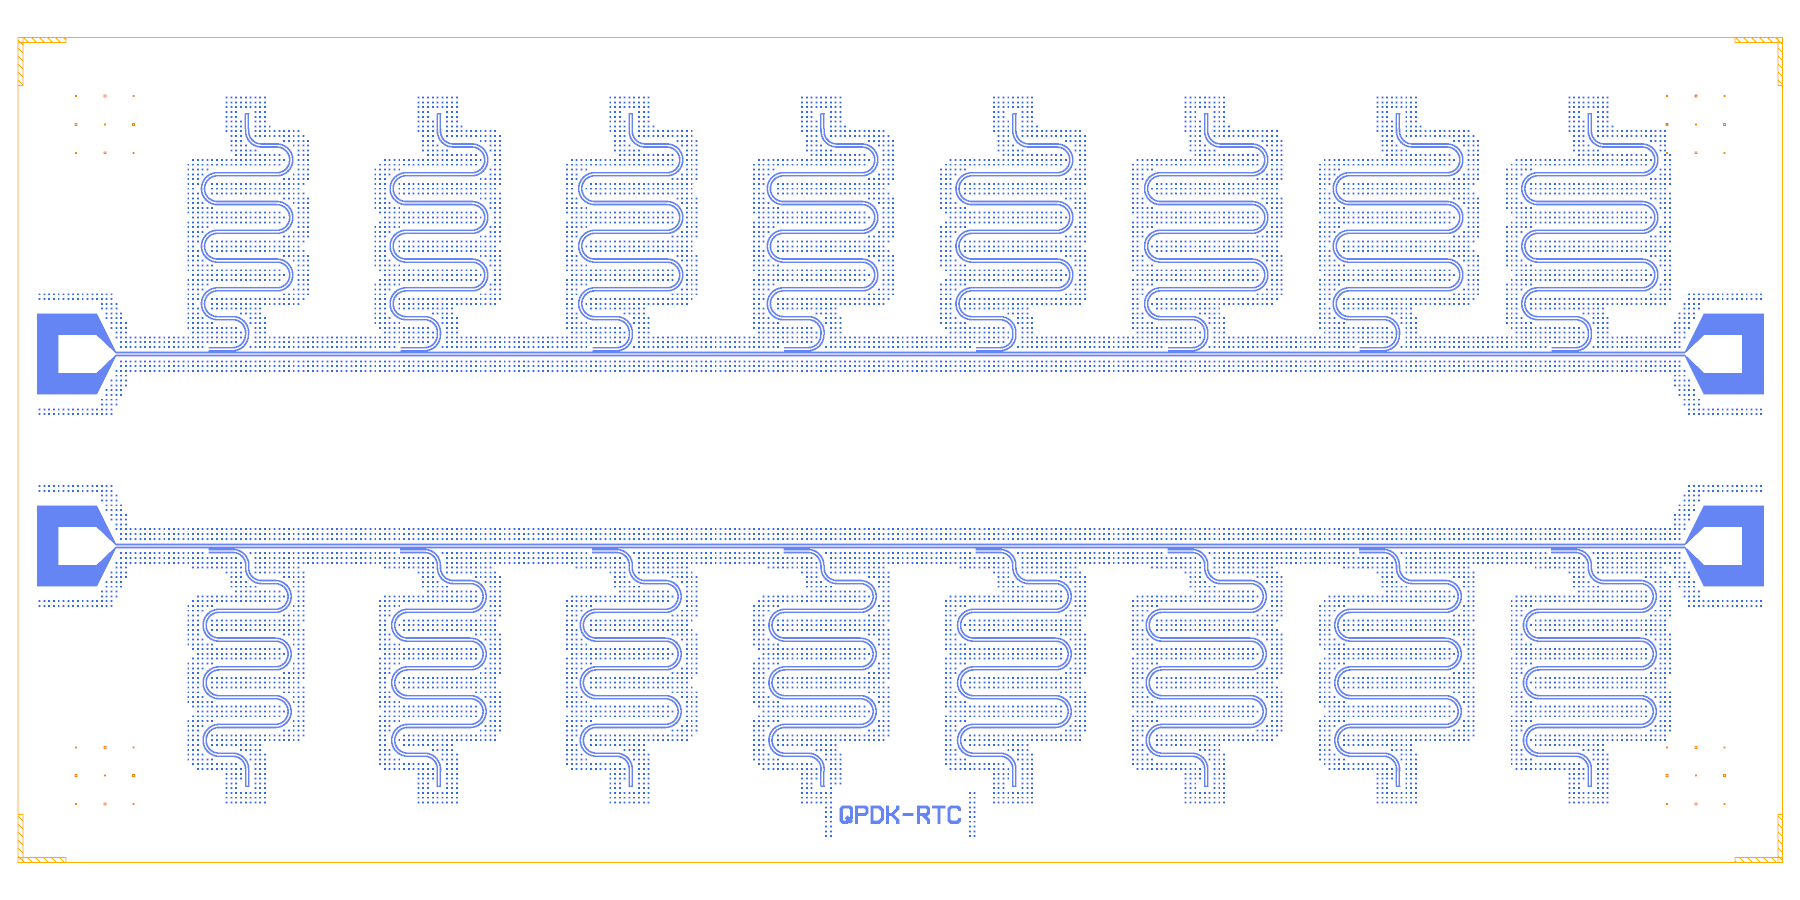

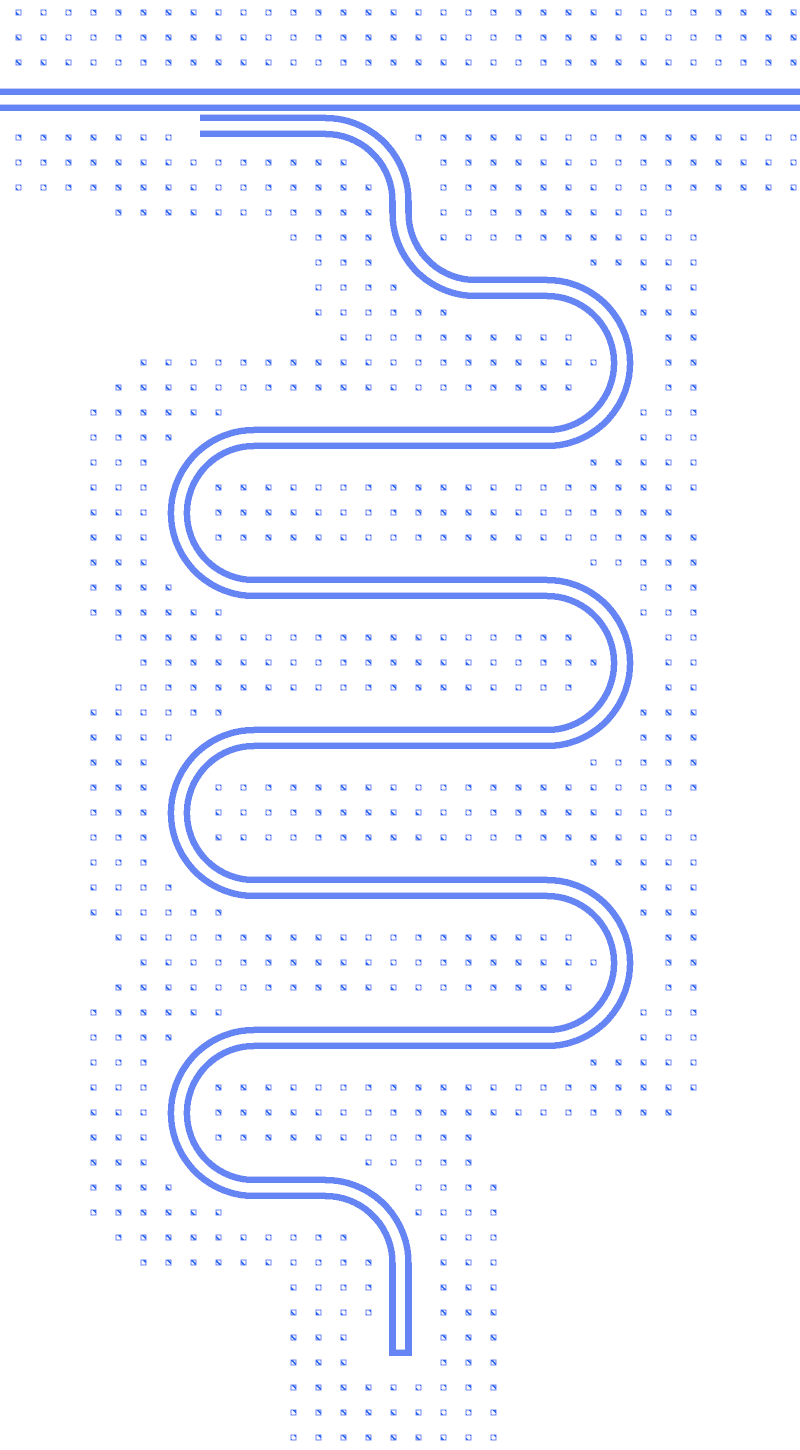

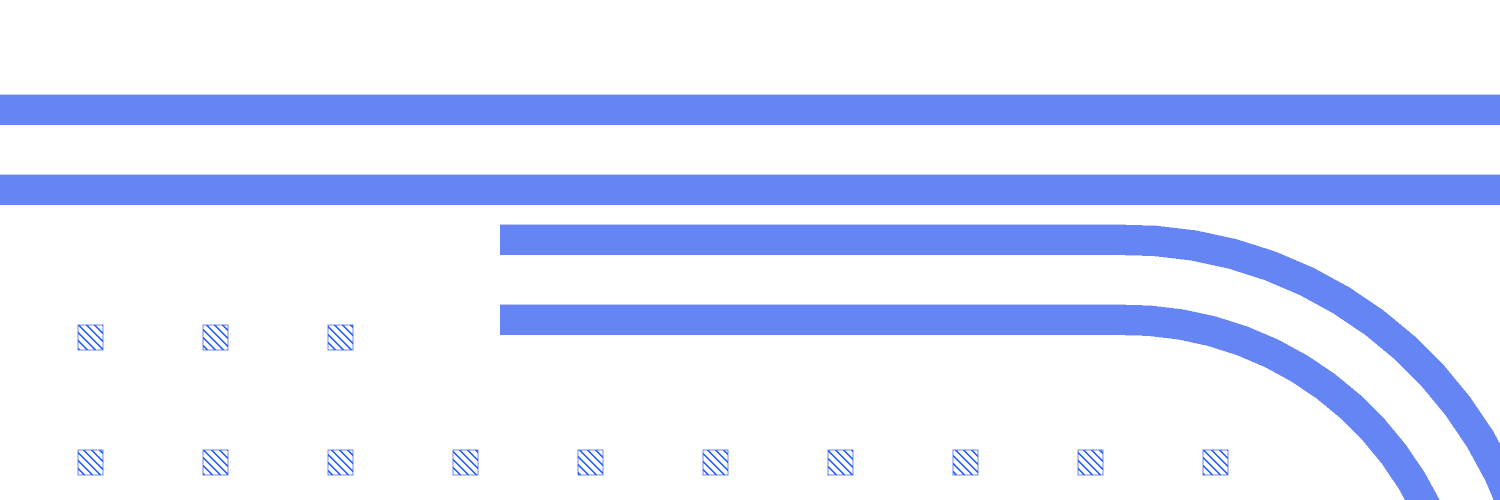

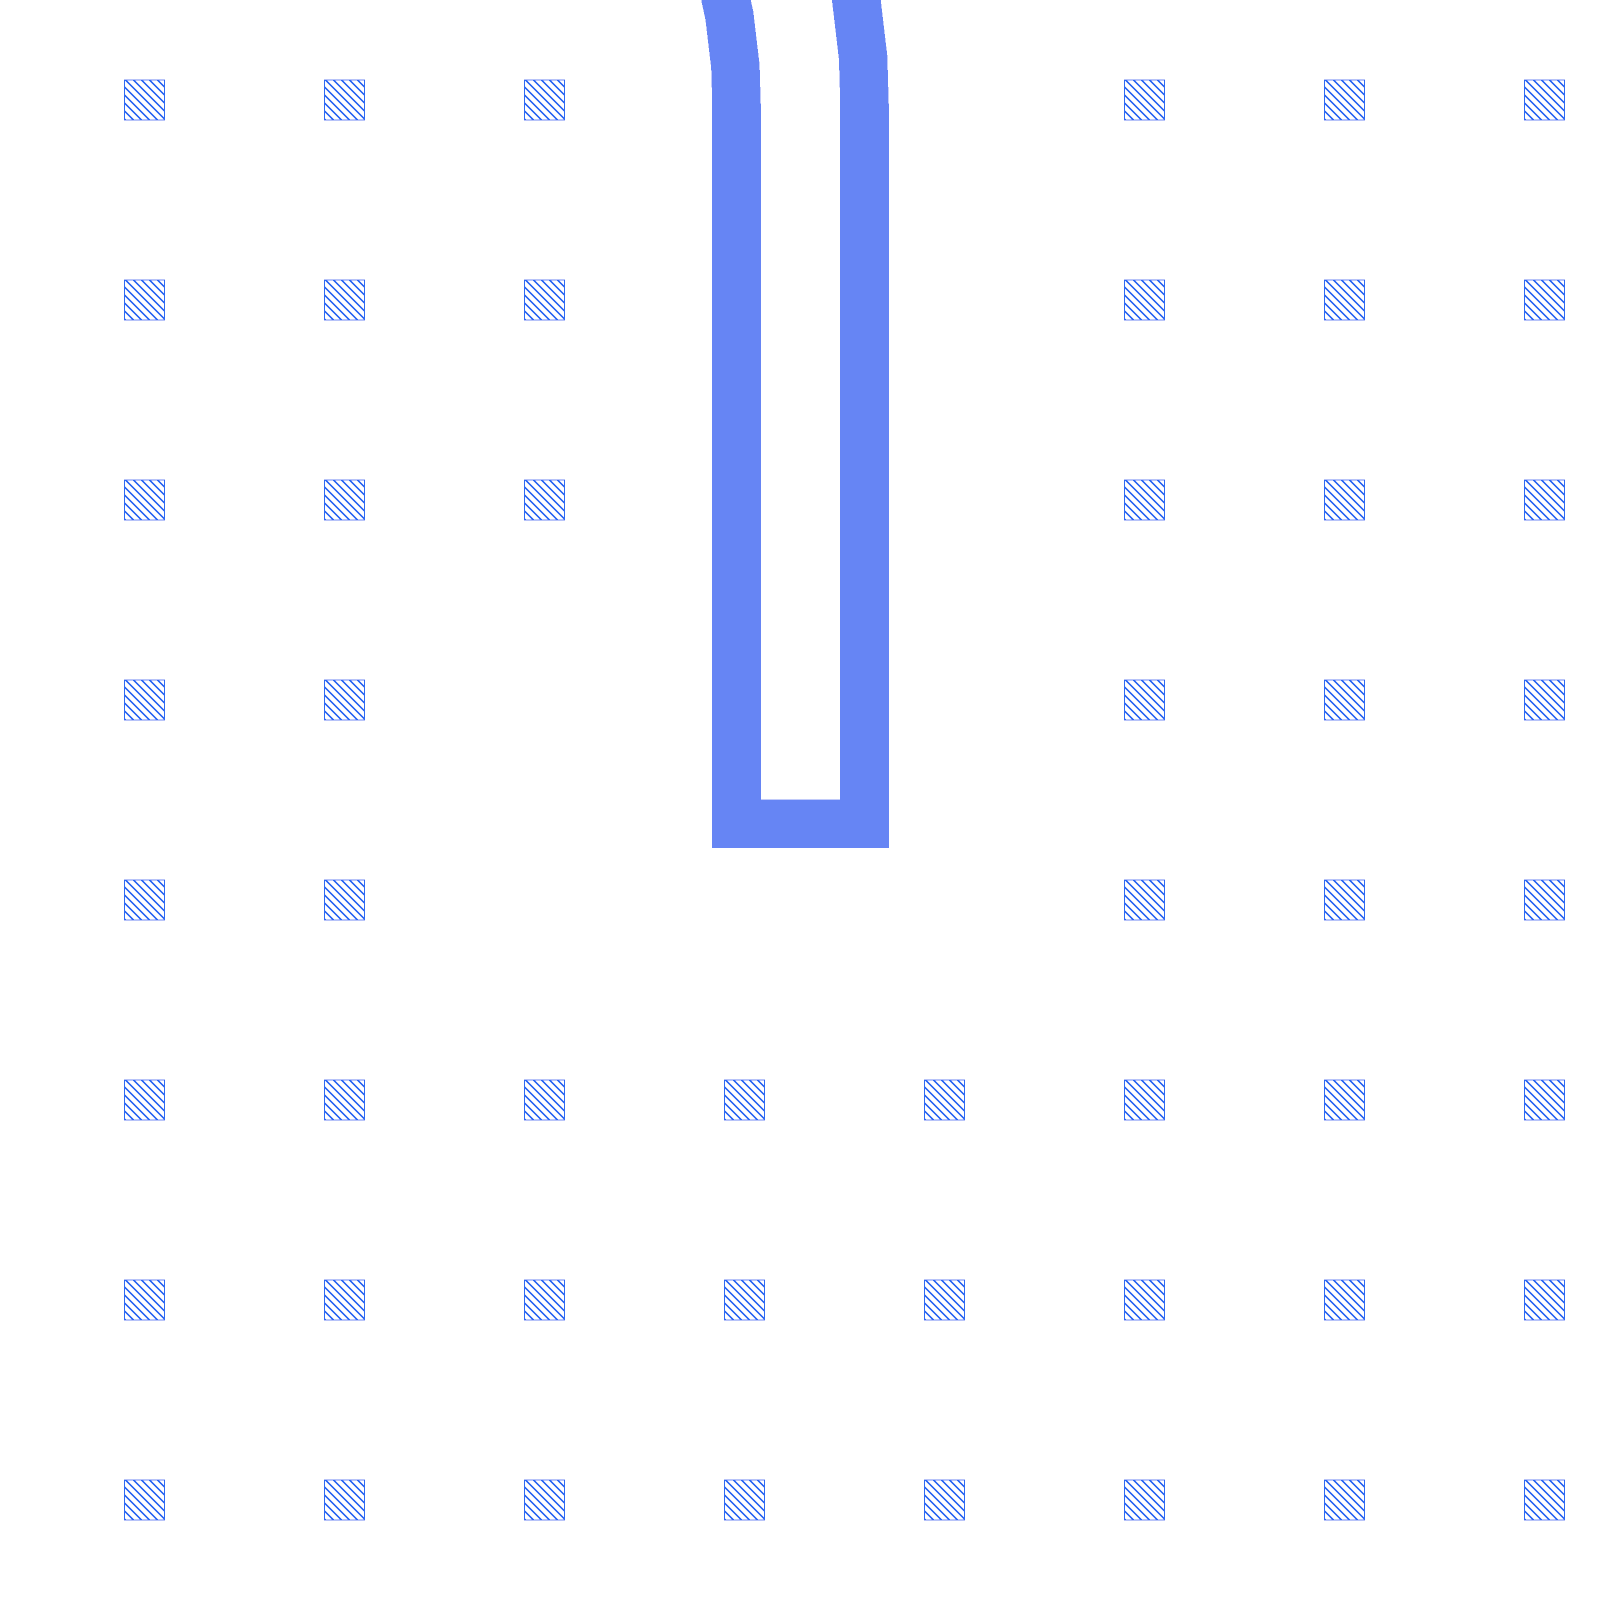

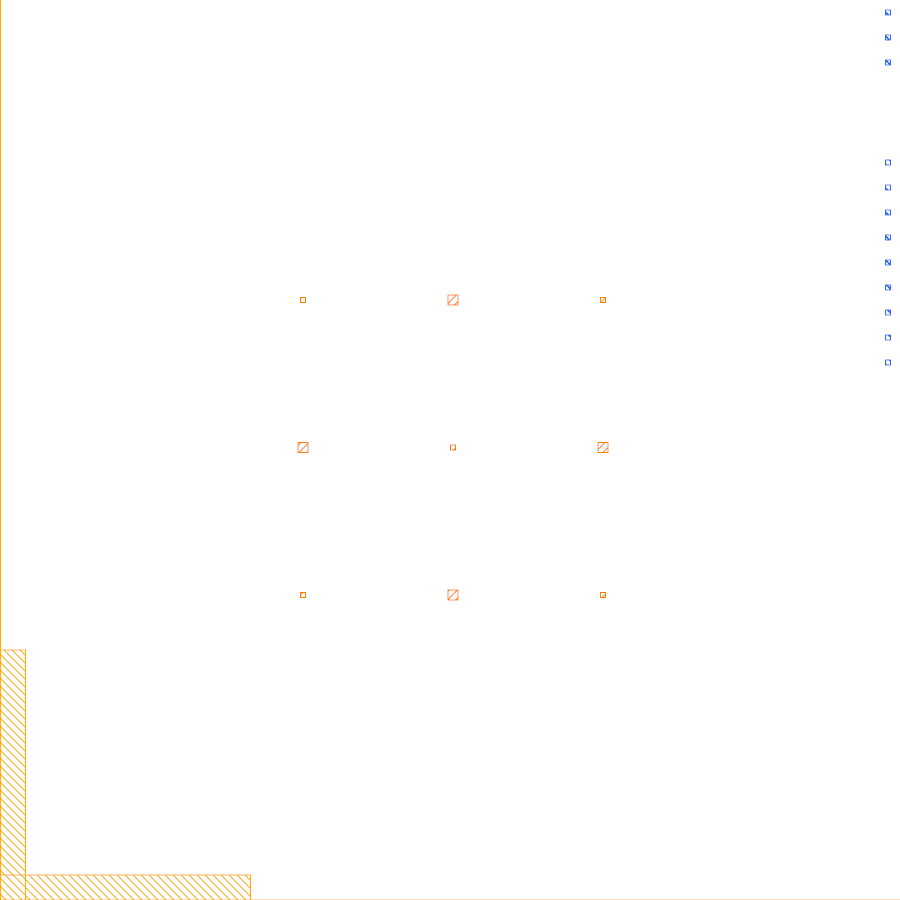

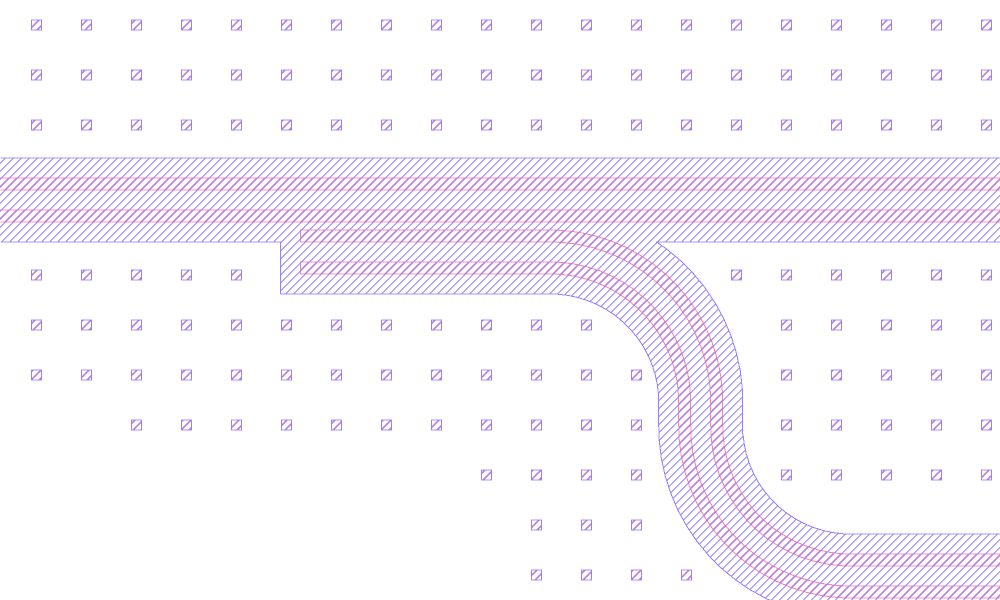

In [17]:
SX, SY = SHIFT


def box(x0, y0, x1, y1):                         # a source-frame box, moved with the centring shift
    return (x0 + SX, y0 + SY, x1 + SX, y1 + SY)


show_snapshot(d, OUT / "resonator_test_chip.png", size=(1800, 900), width=720)
show_snapshot(d, OUT / "resonator_test_chip_rb1.png", box=box(900, 300, 1700, 1750), size=(800, 1450), width=360)
show_snapshot(d, OUT / "resonator_test_chip_short.png", box=box(1000, 1580, 1300, 1680), size=(1500, 500), width=480)
show_snapshot(d, OUT / "resonator_test_chip_open.png", box=box(1200, 330, 1400, 470), width=300)
show_snapshot(d, OUT / "resonator_test_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "resonator_test_chip_fab.oas", OUT / "resonator_test_chip_fab_rb1.png",
          box=box(950, 1450, 1450, 1750), size=(1000, 600), width=480);

**The original.** gdsfactory is not installed in this environment, so the source is not rebuilt here; QPDK's own
render is shown from the local clone when present.

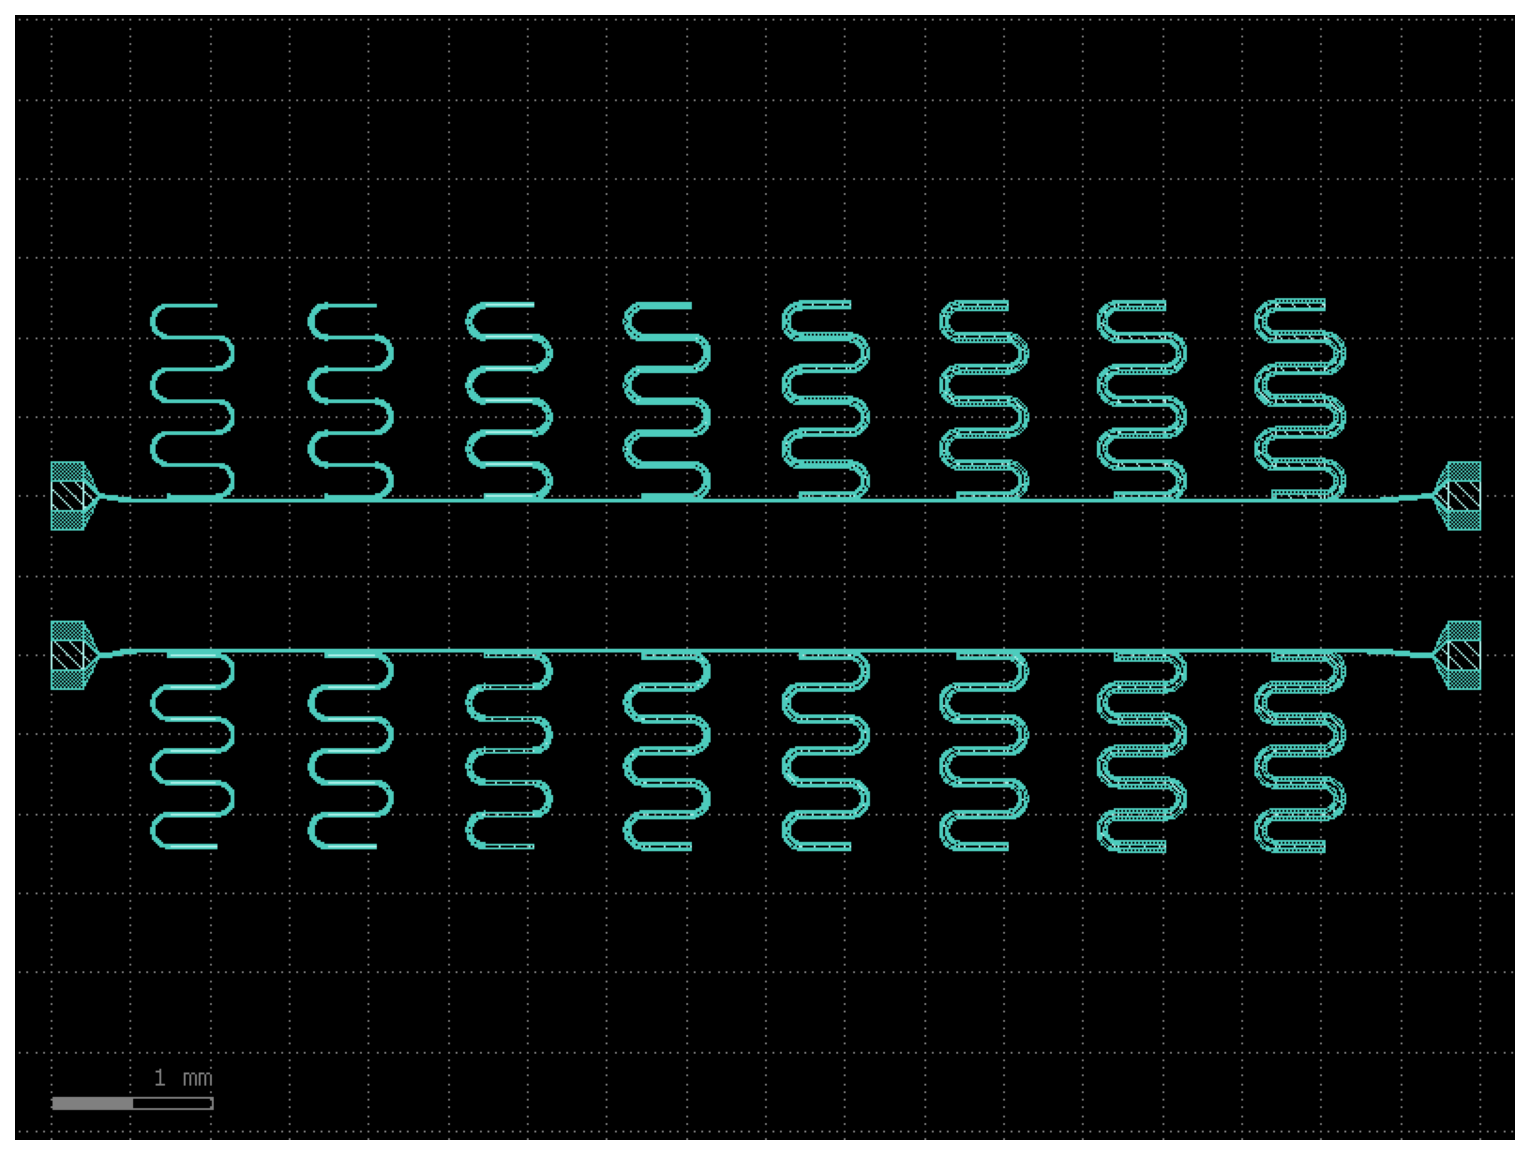

In [18]:
SRC_IMG = Path("build/external/quantum-rf-pdk/docs/_static/images") / "resonator_test_chip.png"   # QPDK's own render (MIT), from the local clone if present
if SRC_IMG.exists():
    display(Image(filename=str(SRC_IMG), width=420))
else:
    print("QPDK image not in this checkout: "
          "https://github.com/gdsfactory/quantum-rf-pdk/blob/main/docs/_static/images/resonator_test_chip.png")

## 15 · Summary

| | |
|---|---|
| **matches the source** | the two probelines and their launchers, the 16 resonator lengths, the 1000 µm pitch, the 200 µm coupled sections with the 16 µm gap, shorted west ends, 6 meanders, the 6 µm open ends |
| **differs (PDK)** | the Quantcore die frame; pads 100 µm in from the edge; the resonators centred (−106 µm in x); couplers anchored by `near=`; sapphire; the PDK cheese band |
| **simplified** | straight probelines (no S-bends at the launchers); router meanders |
| **PDK design warnings** | none |
| **FEM** | 2 eigenmode/EPR jobs exported to `build/jobs/resonator_test_chip_*`, not solved here |